# Desafios Extras!

## Esses desafios são baseados em desafios reais para entrevistas de vagas para ciência de dados e machine learning


> **Sobre os dados:** este exercício é inspirado no desafio de *take-home* de ciência de dados da Uber (cadastro de novos motoristas), amplamente divulgado na internet. A empresa do cenário é um app de mobilidade fictício e os dados são **100% simulados**: não há afiliação com a Uber, e nenhum número aqui representa dados reais da empresa ou das cidades citadas.

In [1]:
import pandas as pd

In [2]:
from pathlib import Path

# Os dados ficam na pasta 'dados/' do repositório no GitHub
arquivo_local = Path("dados/dados_simulados_motoristas.csv")
url = "https://raw.githubusercontent.com/debs-b/desafio-uber/main/dados/dados_simulados_motoristas.csv"

# Se você clonou o repositório, lê o arquivo local; senão (ex.: Google Colab), baixa direto do GitHub
if arquivo_local.exists():
    dados = pd.read_csv(arquivo_local)
    print("Dados carregados do arquivo local!")
else:
    dados = pd.read_csv(url)
    print("Dados carregados do GitHub com sucesso!")

# Visualizando as primeiras linhas dos dados
dados.head()

Dados carregados do arquivo local!


,id,city_name,signup_os,signup_channel,signup_date,bgc_date,vehicle_added_date,first_completed_date,vehicle_make,vehicle_model,vehicle_year
0,1,Vila Rica,windows,Organic,1/3/23,1/5/23,1/12/23,2/1/23,Toyota,Camry,2014.0
1,2,Vila Rica,other,Paid,1/23/23,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Vale do Sol,ios web,Referral,1/21/23,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Vale do Sol,android web,Paid,1/17/23,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Vila Rica,android web,Organic,1/20/23,1/22/23,1/29/23,2/6/23,Subaru,Forester,2016.0


In [3]:
# Dicionário de dados: o que significa cada coluna do dataset
colunas_descricao = {
    "Nome da Coluna": [
        "id", "city_name", "signup_os", "signup_channel", "signup_date",
        "bgc_date", "vehicle_added_date", "first_completed_date", "vehicle_make",
        "vehicle_model", "vehicle_year"
    ],
    "Descrição": [
        "Identificador único do motorista.",
        "Cidade onde o motorista se cadastrou.",
        "Plataforma usada no cadastro ('ios web', 'android web', 'windows', 'mac', 'other').",
        "Canal pelo qual o motorista se cadastrou ('Paid', 'Organic', 'Referral').",
        "Data de criação da conta; no formato ‘M/D/AA’ (ex.: 1/23/23).",
        "Data em que o motorista deu consentimento para a verificação de antecedentes (não indica aprovação); no formato ‘M/D/AA’.",
        "Data em que as informações do veículo do motorista foram enviadas; no formato ‘M/D/AA’.",
        "Data da primeira viagem concluída como motorista; no formato ‘M/D/AA’.",
        "Marca do veículo cadastrado (ex.: Toyota, Honda, Nissan).",
        "Modelo do veículo cadastrado (ex.: Corolla, Civic, Camry).",
        "Ano de fabricação do veículo; no formato ‘AAAA’."
    ]
}

descricao_df = pd.DataFrame(colunas_descricao)

In [4]:
pd.set_option('display.max_columns', None)  # or 1000
pd.set_option('display.max_rows', None)  # or 1000
pd.set_option('display.max_colwidth', None)  # or 199

In [5]:
# Exibindo o DataFrame
descricao_df

,Nome da Coluna,Descrição
0,id,Identificador único do motorista.
1,city_name,Cidade onde o motorista se cadastrou.
2,signup_os,"Plataforma usada no cadastro ('ios web', 'android web', 'windows', 'mac', 'other')."
3,signup_channel,"Canal pelo qual o motorista se cadastrou ('Paid', 'Organic', 'Referral')."
4,signup_date,Data de criação da conta; no formato ‘M/D/AA’ (ex.: 1/23/23).
5,bgc_date,Data em que o motorista deu consentimento para a verificação de antecedentes (não indica aprovação); no formato ‘M/D/AA’.
6,vehicle_added_date,Data em que as informações do veículo do motorista foram enviadas; no formato ‘M/D/AA’.
7,first_completed_date,Data da primeira viagem concluída como motorista; no formato ‘M/D/AA’.
8,vehicle_make,"Marca do veículo cadastrado (ex.: Toyota, Honda, Nissan)."
9,vehicle_model,"Modelo do veículo cadastrado (ex.: Corolla, Civic, Camry)."


In [6]:
# As colunas de data vêm como texto no formato mês/dia/ano (ex.: 1/23/23).
# Convertemos todas para datetime uma única vez, logo no início, informando o formato:
# assim o pandas não precisa "adivinhar" o formato (o que gera avisos e pode errar a leitura).
# errors='coerce' transforma valores vazios em NaT (o "nulo" das datas).
colunas_data = ['signup_date', 'bgc_date', 'vehicle_added_date', 'first_completed_date']

for coluna in colunas_data:
    dados[coluna] = pd.to_datetime(dados[coluna], format='%m/%d/%y', errors='coerce')

dados[colunas_data].dtypes

signup_date             datetime64[ns]
bgc_date                datetime64[ns]
vehicle_added_date      datetime64[ns]
first_completed_date    datetime64[ns]
dtype: object

# Pergunta 1:
## Proponha e defina a métrica principal de sucesso do app redesenhado. Quais são 2-3 métricas adicionais de acompanhamento que serão importantes monitorar além da métrica principal definida?
## O foco principal é melhorar a experiência dos motoristas!

In [7]:
# Verificar valores nulos em cada coluna
analise_nulos = dados.isnull().sum()

# Verificar a proporção de valores nulos
proporcao_nulos = (analise_nulos / len(dados)) * 100

# Consolidar em um DataFrame para facilitar a leitura
# (o índice já traz o nome de cada coluna, então não precisamos repeti-lo)
resumo_nulos = pd.DataFrame({
    'Valores Nulos': analise_nulos,
    'Proporção de Nulos (%)': proporcao_nulos.round(2)
}).sort_values(by='Proporção de Nulos (%)', ascending=False)

resumo_nulos

,Valores Nulos,Proporção de Nulos (%)
first_completed_date,47953,87.19
vehicle_added_date,39057,71.01
vehicle_make,39057,71.01
vehicle_year,39057,71.01
vehicle_model,39057,71.01
bgc_date,19257,35.01
id,0,0.00
signup_os,0,0.00
city_name,0,0.00
signup_channel,0,0.00


In [8]:
# só olhando para os nulos, o que você acha dessa análise inicial?

In [9]:
# Análise

In [10]:
# Possíveis métricas a serem criadas com base nos dados fornecidos
# Primeiro, vamos entender o contexto: um app de mobilidade (fictício) redesenhou o app dos motoristas e quer saber se o novo design melhora o engajamento de novos motoristas.

## O que já temos no dataset:

    Motoristas ativos:
    Podemos identificar motoristas ativos verificando a existência de uma data válida em first_completed_date, indicando que eles completaram pelo menos uma viagem.

    Canais e dispositivos de cadastro:
    Informações como signup_channel e signup_os podem ajudar a entender padrões de engajamento (ex.: motoristas que se cadastram via canal "referral" podem ter comportamentos diferentes).

    Tempo entre etapas:
    Calculando a diferença entre:
        signup_date e first_completed_date (tempo para fazer a primeira viagem).
        signup_date e vehicle_added_date (tempo para adicionar informações do veículo).
        bgc_date e first_completed_date (tempo desde o consentimento para a verificação de antecedentes até a primeira viagem).

    Ano do veículo (vehicle_year):
    Pode ser usado para derivar se motoristas com carros mais novos ou antigos têm maior engajamento.

Taxa de Motoristas Ativos:

Essa métrica indicará a proporção de motoristas que completaram pelo menos uma viagem.

Lógica: Motoristas podem se cadastrar mas nunca fazer sua primeira viagem. A proporção de motoristas que fizeram sua primeira viagem (ativos) / total de motoristas é a métrica que estamos interessados como métrica principal.

In [11]:
# Identificando motoristas ativos (que possuem uma data de primeira viagem)
motoristas_ativos = dados[dados['first_completed_date'].notnull()]

# Calculando a taxa de motoristas ativos
taxa_motoristas_ativos = (len(motoristas_ativos) / len(dados)) * 100

print(f"Taxa de Motoristas Ativos: {taxa_motoristas_ativos:.2f}%")


Taxa de Motoristas Ativos: 12.81%


## Metrica: Taxa de Ativacao de Novos Motoristas

# O que você acha desse valor?
## Quais possíveis hipóteses justificariam esse valor?

Outras métricas ajudam a entender qual o grande desafio para os motoristas serem ativos.

## Sub metrica: Taxa de Motoristas que adicionaram informacoes do veiculo

In [12]:
# Taxa de Motoristas que Adicionaram o Veículo
motoristas_com_veiculo = dados[dados['vehicle_added_date'].notnull()]
taxa_motoristas_veiculo = (len(motoristas_com_veiculo) / len(dados)) * 100

print(f"Taxa de Motoristas que adicionaram informações do veículo: {taxa_motoristas_veiculo:.2f}%")


Taxa de Motoristas que adicionaram informações do veículo: 28.99%


## Sub Metrica: Taxa de Motoristas que Consentiram com a Verificação de Antecedentes
Atenção: `bgc_date` é a data em que o motorista **consentiu** com a verificação de antecedentes, não a data de aprovação. O dataset não diz quem foi aprovado.

In [13]:
# Taxa de Motoristas que consentiram com a Verificação de Antecedentes (BGC)
# Atenção: bgc_date é a data do CONSENTIMENTO, não da aprovação.
motoristas_bgc = dados[dados['bgc_date'].notnull()]
taxa_motoristas_bgc = (len(motoristas_bgc) / len(dados)) * 100

print(f"Taxa de Motoristas que consentiram com a verificação de antecedentes: {taxa_motoristas_bgc:.2f}%")


Taxa de Motoristas que consentiram com a verificação de antecedentes: 64.99%


## Sub Metricas de tempo: Tempo médio entre cadastro e envio de informações do veículo e Tempo médio entre cadastro e primeira viagem

In [14]:
# Tempo medio entre etapas
# Calculando o tempo médio entre etapas (em dias)
tempo_cadastro_para_veiculo = (dados['vehicle_added_date'] - dados['signup_date']).dt.days
tempo_cadastro_para_viagem = (dados['first_completed_date'] - dados['signup_date']).dt.days

# Excluindo valores nulos
tempo_cadastro_para_veiculo_medio = tempo_cadastro_para_veiculo.dropna().mean()
tempo_cadastro_para_viagem_medio = tempo_cadastro_para_viagem.dropna().mean()

print(f"Tempo médio entre cadastro e envio de informações do veículo: {tempo_cadastro_para_veiculo_medio:.2f} dias")
print(f"Tempo médio entre cadastro e primeira viagem: {tempo_cadastro_para_viagem_medio:.2f} dias")


Tempo médio entre cadastro e envio de informações do veículo: 5.07 dias
Tempo médio entre cadastro e primeira viagem: 12.58 dias


In [15]:
# Taxas por canal de cadastro
# Calculando a taxa de motoristas ativos por canal de cadastro
taxas_por_canal = dados.groupby('signup_channel')['first_completed_date'].apply(lambda x: x.notnull().mean() * 100)

print("Taxas de motoristas ativos por canal de cadastro:")
print(taxas_por_canal)


Taxas de motoristas ativos por canal de cadastro:
signup_channel
Organic     12.986722
Paid         7.475282
Referral    20.084955
Name: first_completed_date, dtype: float64


In [16]:
# Ativação por canal: duas perguntas diferentes, com denominadores diferentes
ativado = dados['first_completed_date'].notnull()

tabela_canais = pd.DataFrame({
    'Cadastros': dados.groupby('signup_channel').size(),
    'Ativados': ativado.groupby(dados['signup_channel']).sum(),
})

# % Ativados no Canal: ativados do canal / cadastros do canal
tabela_canais['% Ativados no Canal'] = tabela_canais['Ativados'] / tabela_canais['Cadastros'] * 100

# % do Total de Ativados: ativados do canal / total de ativados (todos os canais)
tabela_canais['% do Total de Ativados'] = tabela_canais['Ativados'] / tabela_canais['Ativados'].sum() * 100

tabela_canais = tabela_canais.sort_values('% Ativados no Canal', ascending=False).round(2)
tabela_canais

,Cadastros,Ativados,% Ativados no Canal,% do Total de Ativados
signup_channel,,,,
Referral,17421,3499,20.08,49.65
Organic,13406,1741,12.99,24.71
Paid,24173,1807,7.48,25.64


In [17]:
# Conversão etapa a etapa do funil: de quem chegou na etapa anterior, quantos avançaram?
# (No dataset, uma etapa só acontece se a anterior aconteceu, então podemos dividir as contagens.)
total_cadastros = len(dados)
total_bgc = dados['bgc_date'].notnull().sum()
total_veiculo = dados['vehicle_added_date'].notnull().sum()
total_ativos = dados['first_completed_date'].notnull().sum()

print(f"Cadastro -> Consentimento para checagem (BGC): {total_bgc / total_cadastros * 100:.1f}%")
print(f"Consentimento (BGC) -> Veículo adicionado: {total_veiculo / total_bgc * 100:.1f}%")
print(f"Veículo adicionado -> Primeira viagem: {total_ativos / total_veiculo * 100:.1f}%")


Cadastro -> Consentimento para checagem (BGC): 65.0%
Consentimento (BGC) -> Veículo adicionado: 44.6%
Veículo adicionado -> Primeira viagem: 44.2%


In [18]:
# Compilação de métricas

# Consolidando as métricas calculadas
metricas = {
    "Métrica": [
        "Taxa de Motoristas Ativos",
        "Taxa de Motoristas que Adicionaram o Veículo",
        "Taxa de Motoristas que Consentiram com a Verificação de Antecedentes",
        "Tempo Médio entre Cadastro e Envio de Informações do Veículo",
        "Tempo Médio entre Cadastro e Primeira Viagem",
        "Taxa de Motoristas Ativos por Canal (Referral)",
        "Taxa de Motoristas Ativos por Canal (Paid)",
        "Taxa de Motoristas Ativos por Canal (Organic)"
    ],
    "Valor": [
        taxa_motoristas_ativos,
        taxa_motoristas_veiculo,
        taxa_motoristas_bgc,
        tempo_cadastro_para_veiculo_medio,
        tempo_cadastro_para_viagem_medio,
        taxas_por_canal["Referral"],
        taxas_por_canal["Paid"],
        taxas_por_canal["Organic"]
    ],
    "Descrição": [
        "Proporção de motoristas cadastrados que completaram pelo menos uma viagem.",
        "Proporção de motoristas que adicionaram informações do veículo após o cadastro.",
        "Proporção de motoristas que deram consentimento para a verificação de antecedentes.",
        "Tempo médio (em dias) desde o cadastro até o envio das informações do veículo.",
        "Tempo médio (em dias) desde o cadastro até a realização da primeira viagem.",
        "Proporção dos motoristas cadastrados pelo canal 'Referral' que completaram a primeira viagem.",
        "Proporção dos motoristas cadastrados pelo canal 'Paid' que completaram a primeira viagem.",
        "Proporção dos motoristas cadastrados pelo canal 'Organic' que completaram a primeira viagem."
    ]
}

# Criando o DataFrame
df_metricas = pd.DataFrame(metricas)

# Exibindo o DataFrame
df_metricas


,Métrica,Valor,Descrição
0,Taxa de Motoristas Ativos,12.812727,Proporção de motoristas cadastrados que completaram pelo menos uma viagem.
1,Taxa de Motoristas que Adicionaram o Veículo,28.987273,Proporção de motoristas que adicionaram informações do veículo após o cadastro.
2,Taxa de Motoristas que Consentiram com a Verificação de Antecedentes,64.987273,Proporção de motoristas que deram consentimento para a verificação de antecedentes.
3,Tempo Médio entre Cadastro e Envio de Informações do Veículo,5.065922,Tempo médio (em dias) desde o cadastro até o envio das informações do veículo.
4,Tempo Médio entre Cadastro e Primeira Viagem,12.575706,Tempo médio (em dias) desde o cadastro até a realização da primeira viagem.
5,Taxa de Motoristas Ativos por Canal (Referral),20.084955,Proporção dos motoristas cadastrados pelo canal 'Referral' que completaram a primeira viagem.
6,Taxa de Motoristas Ativos por Canal (Paid),7.475282,Proporção dos motoristas cadastrados pelo canal 'Paid' que completaram a primeira viagem.
7,Taxa de Motoristas Ativos por Canal (Organic),12.986722,Proporção dos motoristas cadastrados pelo canal 'Organic' que completaram a primeira viagem.


# Quais conclusões podemos tirar dessas métricas?

## manter o foco! Um grande problema de candidatos é perder o foco em exercícios de ciência de dados. Qual era a pergunta:
## Proponha e defina a métrica principal de sucesso do app redesenhado. Quais são 2-3 métricas adicionais de acompanhamento que serão importantes monitorar além da métrica principal definida?


## Resposta:
A métrica principal é a **Taxa de Motoristas Ativos** (taxa de ativação): a proporção de motoristas cadastrados que fizeram a primeira viagem. Hoje ela é de 12.81%, um valor baixo.

Como métricas de acompanhamento (2-3, como a pergunta pede), escolhemos as que mostram **onde** os motoristas param no caminho até a primeira viagem:
1. Taxa de Motoristas que Adicionaram o Veículo (28.99%)
2. Tempo Médio entre Cadastro e Primeira Viagem (12.58 dias)
3. Taxa de Motoristas Ativos por Canal (Referral 20.08%, Organic 12.99%, Paid 7.48%)

A maioria dos candidatos, 64.99%, dá consentimento para a checagem de antecedentes, mas apenas 28.99% adicionam o veículo. Etapa a etapa (célula acima): 44.6% de quem consentiu adiciona o veículo, e 44.2% de quem adicionou o veículo faz a primeira viagem, ou seja, as duas últimas etapas perdem mais da metade dos motoristas cada. Atenção: como `bgc_date` registra o consentimento e não a aprovação, parte da perda depois dessa etapa pode vir de reprovação ou demora na checagem.

Sobre os canais: **Referral** (indicação) é o canal com a maior taxa de ativação (20.08%), seguido de Organic (12.99%) e Paid (7.48%). Isso mostra o sucesso dos programas de indicação e sugere maiores investimentos neles.

Percebeu que foi pouco código para muito insight? Isso é ciência de dados! Há momentos de só ficar no código, e momentos de analisar os resultados e trazer ganhos ao negócio!

### Resumo insights: Olhando para os dados brutos, a maioria dos candidatos foca em código. O cientista de dados sênior foca no padrão: 64.99% dos motoristas dão consentimento para a checagem de antecedentes (BGC), mas apenas 28.99% adicionam um veículo e só 12.81% fazem a primeira viagem.
#### Depois do consentimento, cada etapa perde mais da metade dos motoristas (44.6% adicionam o veículo; desses, 44.2% fazem a primeira viagem). Como o dataset registra só o consentimento da checagem (e não a aprovação), não dá para culpar apenas a tela de veículo: o novo design precisa atacar o cadastro do veículo **e** o caminho até a primeira viagem, e vale pedir os dados de aprovação da checagem para separar os dois efeitos.

# Pergunta 2: Descreva um plano de teste para avaliar se o app redesenhado apresenta melhor desempenho (de acordo com as métricas que você definiu). Como você equilibraria a necessidade de obter resultados rápidos, com rigor estatístico e ainda monitorando riscos?

## Resposta: Teste A/B

## O Desenho do Experimento (Split de Usuários):

   * Unidade de Randomização: O motorista (baseado no id). Como o marketplace de um app de mobilidade é dinâmico, randomizar por motorista em uma mesma cidade pode gerar efeito de rede (network effects / interferência).

   * Idealmente o correto seria um Cluster-Based A/B Test (ex: dividir por cidades inteiras ou regiões bem definidas).
   
   * Para simplificar o código, assumiremos um split clássico por usuário, mas trazendo esse alerta de negócio.

## Dimensionamento Estatístico (Sample Size & MDE):
* Métrica Principal: Taxa de Ativação (Base atual: ~12.81%).

* Janela de ativação: no teste, medimos a ativação **em até 30 dias após o cadastro**. Sem uma janela fixa, quem se cadastrou antes tem mais tempo para fazer a primeira viagem, e a comparação entre os grupos fica injusta. No histórico, 91.7% das ativações acontecem em até 30 dias.

* MDE (Efeito Mínimo Detectável): Definir o quanto de melhoria queremos detectar que faça sentido financeiro (ex: aumentar a ativação em 2 pontos percentuais (p.p.), indo de 12.81% para 14.81%).

* Poder Estatístico ($1 - \beta$): 80%.

* Significância ($\alpha$): 5% (p-valor < 0.05).

* Duração: O teste deve rodar por ciclos completos de semanas (mínimo 2 semanas, idealmente 4 semanas devido ao ciclo de ativação de 13 dias do motorista) para evitar sazonalidades de dias de semana vs. finais de semana. Depois de fechar a entrada de novos motoristas no teste, esperamos a janela de 30 dias para medir a ativação de todos.

## Métricas de Guardrail:

* O que monitorar para garantir que o novo app não quebrou o negócio? Taxa de Cancelamento de Viagens e Tempo de Espera do Passageiro (ETA). Se a ativação subir, mas os cancelamentos dispararem porque a nova interface confunde o motorista, o teste deve ser abortado.

* Taxa de Motoristas que Adicionaram o Veículo: Verificar se o redesenho simplifica o processo de adicionar informações do veículo.

* Tempo Médio entre Cadastro e Envio de Informações do Veículo: Avaliar se o redesenho reduz o tempo necessário para essa etapa.

* Tempo Médio entre Cadastro e Primeira Viagem: Identificar se o redesenho agiliza a ativação.

### Riscos a Monitorar:

* Feedback negativo: Analisar comentários e avaliações para identificar possíveis problemas ou insatisfações com o app redesenhado.

* Retenção de longo prazo: Garantir que motoristas do grupo tratamento permaneçam engajados após a ativação inicial.

In [19]:

# Objetivo: Definir o tamanho da amostra (Sample Size) e o tempo de rodada do
# Teste A/B para que ele tenha poder estatístico suficiente: com pouca amostra,
# um efeito real pode passar despercebido (falso negativo).

import statsmodels.stats.api as sms
import numpy as np

print("--- CONFIGURAÇÃO DO EXPERIMENTO ESTATÍSTICO ---")

# 1. Parâmetros de Entrada (Métricas de Negócio do App)
# Usamos a taxa atual de ativação que calculamos na Pergunta 1 como nossa linha de base (Baseline)
taxa_controle_baseline = taxa_motoristas_ativos / 100  # ~0.1281 (ou 12.81%)

# MDE (Minimum Detectable Effect): O menor efeito que o time de produto julga
# relevante para justificar o custo do redesenho. Vamos testar um aumento de 2 pontos percentuais (p.p.).
mde = 0.02
taxa_tratamento_esperada = taxa_controle_baseline + mde

# Parâmetros Estatísticos Padrão de Mercado
alpha = 0.05  # Nível de Significância (Chance de falso positivo tolerada: 5%)
power = 0.80  # Poder Estatístico (Chance de detectar um efeito real: 80%)

print(f"Conversão Atual (Controle): {taxa_controle_baseline*100:.2f}%")
print(f"Conversão Alvo (Tratamento): {taxa_tratamento_esperada*100:.2f}%")
print(f"Efeito Mínimo Detectável (MDE): +{mde*100:.2f} p.p.\n")

# 2. Cálculo do Tamanho de Amostra Necessário
# Calculamos o 'Effect Size' usando a transformação de Cohen (Cohen's h) para proporções
effect_size = sms.proportion_effectsize(taxa_controle_baseline, taxa_tratamento_esperada)

# Resolução do poder estatístico para encontrar o N (tamanho da amostra por grupo)
analise_poder = sms.NormalIndPower()
tamanho_amostra_grupo = analise_poder.solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    ratio=1.0 # Divisão 50/50 entre Grupo Controle e Grupo Tratamento
)

tamanho_amostra_grupo = int(np.ceil(tamanho_amostra_grupo))
amostra_total = tamanho_amostra_grupo * 2

print("--- RESULTADO DO DIMENSIONAMENTO ---")
print(f"Número de motoristas necessários no Grupo Controle: {tamanho_amostra_grupo:,}")
print(f"Número de motoristas necessários no Grupo Tratamento: {tamanho_amostra_grupo:,}")
print(f"Volume total de novos cadastros necessários: {amostra_total:,}\n")

# 3. Estimativa de Tempo de Execução do Teste
# O histórico cobre os cadastros de um mês: usamos a média diária como estimativa de tráfego.
dias_historico = dados['signup_date'].nunique()
cadastros_por_dia = len(dados) / dias_historico
dias_para_amostra = int(np.ceil(amostra_total / cadastros_por_dia))

# Janela de ativação: quantas ativações acontecem em até 30 dias após o cadastro?
dias_ate_ativar = (dados['first_completed_date'] - dados['signup_date']).dt.days
pct_ativacoes_30d = (dias_ate_ativar <= 30).sum() / dias_ate_ativar.notnull().sum() * 100

print(f"O histórico possui {len(dados):,} cadastros em {dias_historico} dias (~{cadastros_por_dia:,.0f} por dia).")
print(f"Para juntar {amostra_total:,} cadastros, bastariam ~{dias_para_amostra} dias de tráfego.")
print(f"{pct_ativacoes_30d:.1f}% das ativações acontecem em até 30 dias do cadastro: por isso medimos a 'ativação em 30 dias'.")

print("\n--- DECISÃO DE PRODUTO & MITIGAÇÃO DE RISCO ---")
print("1. Duração do Teste: Mesmo que a amostra seja atingida antes, o teste deve rodar por ciclos semanais completos (mínimo 14 dias)")
print("   para capturar o comportamento dos motoristas tanto em dias úteis quanto em fins de semana.")
print("   Depois, esperamos 30 dias para medir a ativação de quem entrou por último no teste.")
print("2. Mitigação de Risco: Antes do teste, libere o novo app para uma fração pequena (ex: 10%) só para checar bugs e estabilidade.")
print("   Com tudo estável, rode a divisão 50/50 usada no cálculo acima (um split 90/10 também funciona, mas exige mais cadastros: use ratio=9).")
print("3. Métricas de Guardrail: Se a Taxa de Cancelamento ou o Tempo de Espera (ETA) subirem, e outras métricas de experiência do usuário piorarem,")
print("   o experimento deve ser abortado imediatamente, mesmo que a ativação esteja subindo.")

--- CONFIGURAÇÃO DO EXPERIMENTO ESTATÍSTICO ---
Conversão Atual (Controle): 12.81%
Conversão Alvo (Tratamento): 14.81%
Efeito Mínimo Detectável (MDE): +2.00 p.p.

--- RESULTADO DO DIMENSIONAMENTO ---
Número de motoristas necessários no Grupo Controle: 4,667
Número de motoristas necessários no Grupo Tratamento: 4,667
Volume total de novos cadastros necessários: 9,334

O histórico possui 55,000 cadastros em 31 dias (~1,774 por dia).
Para juntar 9,334 cadastros, bastariam ~6 dias de tráfego.
91.7% das ativações acontecem em até 30 dias do cadastro: por isso medimos a 'ativação em 30 dias'.

--- DECISÃO DE PRODUTO & MITIGAÇÃO DE RISCO ---
1. Duração do Teste: Mesmo que a amostra seja atingida antes, o teste deve rodar por ciclos semanais completos (mínimo 14 dias)
   para capturar o comportamento dos motoristas tanto em dias úteis quanto em fins de semana.
   Depois, esperamos 30 dias para medir a ativação de quem entrou por último no teste.
2. Mitigação de Risco: Antes do teste, libere o 

## Notas:

* Effect Size: Para detectar variações pequenas (como +2 p.p.), o volume de dados necessário cresce bastante. Se quiséssemos detectar um aumento de apenas +0.5 p.p., o tamanho da amostra seria brutalmente maior (cerca de 15 vezes, veja o cálculo abaixo).

* p.p. vs %: ir de 12.81% para 14.81% é um aumento de 2 pontos percentuais (p.p.), mas um aumento *relativo* de ~15.6%. Em entrevistas, deixe claro qual dos dois você está usando.

In [20]:
# Mesmo cálculo, agora para detectar um aumento de apenas +0.5 p.p. (12.81% -> 13.31%)
# Atenção: o effect_size precisa ser calculado a partir das duas taxas (Cohen's h),
# não é o próprio aumento de 0.005.
mde_pequeno = 0.005
effect_size_pequeno = sms.proportion_effectsize(taxa_controle_baseline, taxa_controle_baseline + mde_pequeno)

tamanho_amostra_grupo_pequeno = analise_poder.solve_power(
    effect_size=effect_size_pequeno,
    alpha=alpha,
    power=power,
    ratio=1.0 # Divisão 50/50 entre Grupo Controle e Grupo Tratamento
)

tamanho_amostra_grupo_pequeno = int(np.ceil(tamanho_amostra_grupo_pequeno))
amostra_total_pequeno = tamanho_amostra_grupo_pequeno * 2

print("--- DIMENSIONAMENTO PARA DETECTAR +0.5 p.p. ---")
print(f"Número de motoristas necessários no Grupo Controle: {tamanho_amostra_grupo_pequeno:,}")
print(f"Número de motoristas necessários no Grupo Tratamento: {tamanho_amostra_grupo_pequeno:,}")
print(f"Volume total de novos cadastros necessários: {amostra_total_pequeno:,}")
print(f"Isso é ~{tamanho_amostra_grupo_pequeno / tamanho_amostra_grupo:.0f}x a amostra necessária para detectar +2 p.p.")

--- DIMENSIONAMENTO PARA DETECTAR +0.5 p.p. ---
Número de motoristas necessários no Grupo Controle: 71,302
Número de motoristas necessários no Grupo Tratamento: 71,302
Volume total de novos cadastros necessários: 142,604
Isso é ~15x a amostra necessária para detectar +2 p.p.


* Métricas Guardrail: métricas puras de conversão podem ser enganosas se destruírem o ecossistema do marketplace (ex: ativar mais motoristas, mas que aceitam corridas e cancelam logo em seguida).

# Pergunta 3: Explique como você traduziria os resultados do plano de teste em uma decisão sobre lançar o novo design ou revertê-lo.

## 1. Cenário Ideal (Greenlight)
* Condição: Aumento na Métrica Principal (Taxa de Ativação) é estatisticamente significante ($p < 0.05$) E o ganho é maior ou igual ao MDE definido (ex: +2 p.p. de ativação).

* Métricas Guardrail: Nenhuma métrica de guardrail (como cancelamentos ou reclamações no suporte) piorou de forma significante.

* Decisão: Lançar o novo design via Rollout Gradual (ex: expandir de 10% para 25%, 50% e 100% ao longo de duas semanas para monitorar a carga dos servidores e suporte).

## 2. Cenário a ser Discutido (O Verdadeiro Desafio do Cientista de Dados)
* Condição A (Efeito Estatístico sem Impacto de Negócio): O resultado é estatisticamente significante ($p < 0.05$), mas o aumento real foi de apenas 0.1 p.p..

* Análise: O teste teve muita amostra, mas o ganho não paga o custo de desenvolvimento e treinamento dos motoristas. 

* Decisão: *Reverter* ou *Iterar* (volta ao design e novo teste).



---

* Condição B (Métricas Conflitantes): A taxa de ativação subiu 3 p.p., mas a taxa de cancelamento de viagens também subiu 5 p.p..

* Análise: O novo app facilita o cadastro, mas confunde o motorista na hora de fazer a corrida. 

* Decisão: Abortar o lançamento e devolver para o time de UX/Design.

## 3. Cenário de Falha (Reversão)

* Condição: Sem significância estatística ($p > 0.05$) ou resultado negativo na ativação.

* Decisão: Reverter imediatamente. O design antigo permanece como o campeão (Champion).

### Notas:

* Métrica não é tudo: O novo app pode ser um sucesso para "cadastrar mais rápido", mas um fracasso para o negócio se o motorista começar a cancelar mais viagens por não entender a nova tela.


* Custo de Mudança (Switching Cost): Mudar o aplicativo de milhões de usuários exige custo de servidores, atualização de FAQs, suporte técnico e atrito de aprendizado do usuário. 
* Por isso, se o ganho estatístico for real, mas muito pequeno, a decisão correta de negócio costuma ser não lançar.


## Parte 2: Realize a limpeza de dados necessária, análise exploratória e/ou visualizações utilizando o dataset fornecido (descrições breves ou gráficos que ilustrem sua abordagem são incentivados). Qual a porcentagem de motoristas cadastrados que resultaram em uma primeira viagem?

--- ETAPA 1: TRATAMENTO E LIMPEZA DOS DADOS ---
Tipos das colunas de data:


signup_date             datetime64[ns]
bgc_date                datetime64[ns]
vehicle_added_date      datetime64[ns]
first_completed_date    datetime64[ns]
dtype: object 

Veículos com ano de fabricação inválido (0) convertidos para nulo: 5
Registros com alguma etapa anterior à data de cadastro: 0

--- ETAPA 2: CÁLCULO DA TAXA DE CONVERSÃO FINAL ---
Total de motoristas que iniciaram o cadastro: 55,000
Total de motoristas que realizaram a primeira viagem: 7,047
PORCENTAGEM DE MOTORISTAS ATIVADOS: 12.81%

--- ETAPA 3: GERANDO VISUALIZAÇÕES E INSIGHTS PARA AULA ---


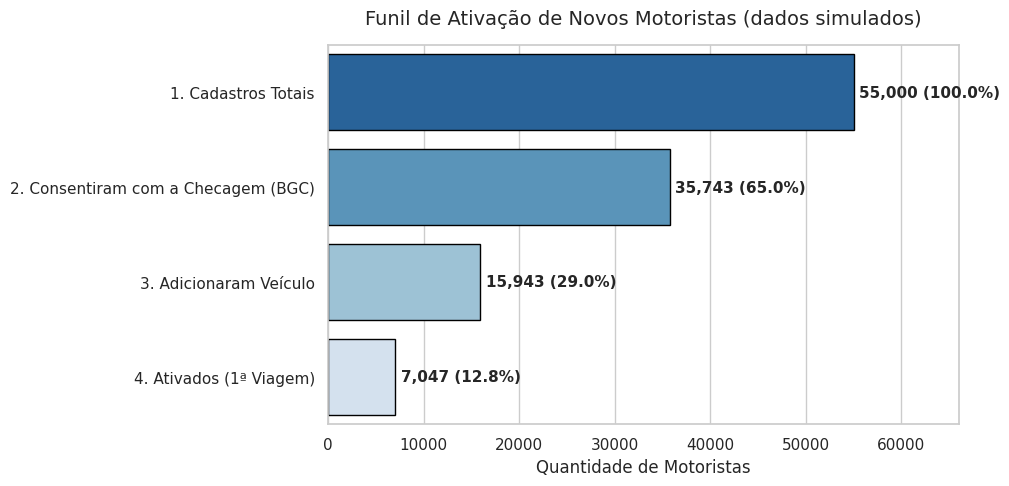

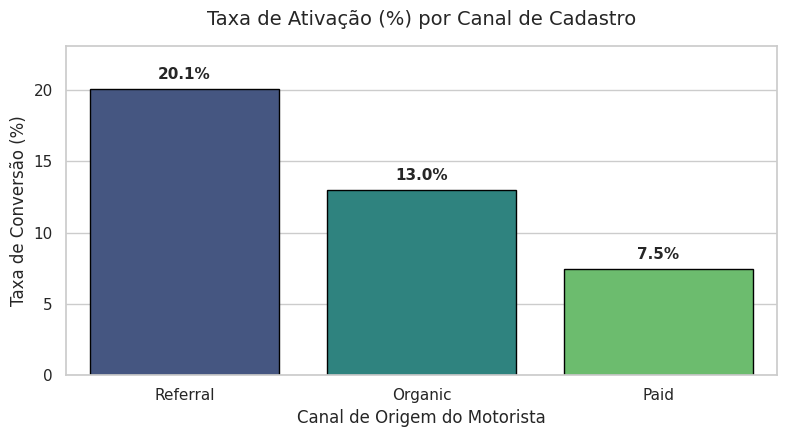

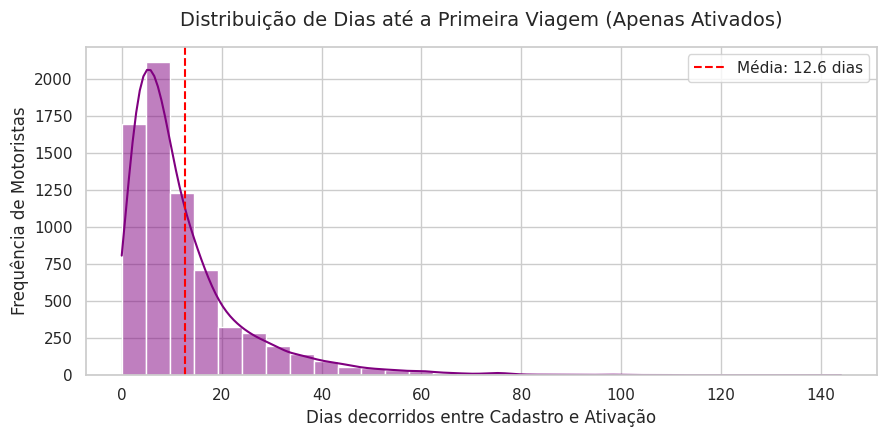

In [21]:

# Objetivo: Realizar a limpeza dos dados, converter tipos de variáveis, 
# responder à pergunta de conversão e gerar gráficos.

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- ETAPA 1: TRATAMENTO E LIMPEZA DOS DADOS ---")

# 1.1 Tipagem: as colunas de data já foram convertidas para datetime logo após a leitura dos dados.
colunas_data = ['signup_date', 'bgc_date', 'vehicle_added_date', 'first_completed_date']
print("Tipos das colunas de data:")
print(dados[colunas_data].dtypes, "\n")

# 1.2 Valores impossíveis: alguns veículos têm ano de fabricação 0 (erro de cadastro).
# Trocamos por nulo (NaN) para não distorcer análises por ano do veículo.
anos_invalidos = (dados['vehicle_year'] == 0).sum()
dados['vehicle_year'] = dados['vehicle_year'].replace(0, np.nan)
print(f"Veículos com ano de fabricação inválido (0) convertidos para nulo: {anos_invalidos}")

# 1.3 Consistência do funil: nenhuma etapa deveria acontecer antes do cadastro.
etapas_antes_do_cadastro = sum(
    (dados[coluna] < dados['signup_date']).sum()
    for coluna in ['bgc_date', 'vehicle_added_date', 'first_completed_date']
)
print(f"Registros com alguma etapa anterior à data de cadastro: {etapas_antes_do_cadastro}\n")


print("--- ETAPA 2: CÁLCULO DA TAXA DE CONVERSÃO FINAL ---")

# Motoristas ativos são aqueles que possuem uma data válida em 'first_completed_date'
total_cadastros = len(dados)
motoristas_ativos = dados[dados['first_completed_date'].notnull()]
total_ativos = len(motoristas_ativos)

taxa_conversao_final = (total_ativos / total_cadastros) * 100

print(f"Total de motoristas que iniciaram o cadastro: {total_cadastros:,}")
print(f"Total de motoristas que realizaram a primeira viagem: {total_ativos:,}")
print(f"PORCENTAGEM DE MOTORISTAS ATIVADOS: {taxa_conversao_final:.2f}%\n")


print("--- ETAPA 3: GERANDO VISUALIZAÇÕES E INSIGHTS PARA AULA ---")

# Configurando o estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# Gráfico 1: O Funil de Conversão Comercial (Onde está o vazamento de receita?)
etapas_funil = [
    '1. Cadastros Totais', 
    '2. Consentiram com a Checagem (BGC)', 
    '3. Adicionaram Veículo', 
    '4. Ativados (1ª Viagem)'
]
valores_funil = [
    total_cadastros,
    dados['bgc_date'].notnull().sum(),
    dados['vehicle_added_date'].notnull().sum(),
    total_ativos
]

plt.figure(figsize=(10, 5))
sns.barplot(x=valores_funil, y=etapas_funil, hue=etapas_funil, palette="Blues_r", edgecolor="black", legend=False)
plt.title('Funil de Ativação de Novos Motoristas (dados simulados)', fontsize=14, pad=15)
plt.xlabel('Quantidade de Motoristas')

# Adicionando rótulos com as porcentagens em relação ao total de cadastros
for i, valor in enumerate(valores_funil):
    porcentagem = (valor / total_cadastros) * 100
    plt.text(valor + (total_cadastros * 0.01), i, f"{valor:,} ({porcentagem:.1f}%)", va='center', fontweight='bold')

plt.xlim(0, total_cadastros * 1.2)
plt.tight_layout()
plt.show()


# Gráfico 2: Comportamento de Ativação por Canal de Aquisição (Signup Channel)
# Queremos saber se canais orgânicos ou indicações ativam melhor que mídia paga.
dados['ativado'] = dados['first_completed_date'].notnull()
taxa_por_canal = dados.groupby('signup_channel')['ativado'].mean() * 100
taxa_por_canal = taxa_por_canal.sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=taxa_por_canal.index, y=taxa_por_canal.values, hue=taxa_por_canal.index, palette="viridis", edgecolor="black", legend=False)
plt.title('Taxa de Ativação (%) por Canal de Cadastro', fontsize=14, pad=15)
plt.ylabel('Taxa de Conversão (%)')
plt.xlabel('Canal de Origem do Motorista')

for i, valor in enumerate(taxa_por_canal.values):
    plt.text(i, valor + 0.5, f"{valor:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.ylim(0, taxa_por_canal.max() * 1.15)
plt.tight_layout()
plt.show()


# Gráfico 3: Distribuição do Tempo de Ativação (Time-to-First-Trip)
# Filtramos apenas os motoristas que de fato completaram uma viagem para ver o delay do processo.
dados_ativos = dados[dados['first_completed_date'].notnull()].copy()
dados_ativos['dias_para_ativar'] = (dados_ativos['first_completed_date'] - dados_ativos['signup_date']).dt.days

plt.figure(figsize=(9, 4.5))
sns.histplot(data=dados_ativos, x='dias_para_ativar', bins=30, kde=True, color="purple")
plt.title('Distribuição de Dias até a Primeira Viagem (Apenas Ativados)', fontsize=14, pad=15)
plt.xlabel('Dias decorridos entre Cadastro e Ativação')
plt.ylabel('Frequência de Motoristas')
plt.axvline(dados_ativos['dias_para_ativar'].mean(), color='red', linestyle='--', label=f"Média: {dados_ativos['dias_para_ativar'].mean():.1f} dias")
plt.legend()
plt.tight_layout()
plt.show()

## Resposta: A porcentagem de motoristas cadastrados que resultaram em uma primeira viagem é de exatamente 12.81%.
( sempre escreva respostas claras e diretas) - comentario da experiencia

### Grafico 2:
#### O poder de negócios desse insight. O canal Referral (Indicação) tem cerca de 2.7 vezes a taxa de conversão do tráfego Paid (Mídia Paga): $20.1\%$ contra $7.5\%$.
#### Motoristas indicados por outros motoristas são muito mais propensos a passar pelas barreiras do app.

### O Delay de Engajamento (Gráfico 3):
#### A média de tempo para fazer a primeira corrida é de 13 dias. Isso prova que o processo de ativação não é imediato;
#### exige um acompanhamento de notificações por push, e-mails de incentivo, etc ao longo das duas primeiras semanas do usuário.

### Dicas finais
* Para responder a primeira pergunta, nós já havíamos feito várias análises. Isso é comum em desafios: às vezes a dica para a pergunta em que você está com dúvidas está na próxima pergunta! Então leia todas as perguntas antes de começar seu exercício.
* Mantenha o código claro e preciso. Mantenha o foco e sempre responda a todas as perguntas. Se sobrar tempo, adicione comentários extras. Seja proativo(a) e criativo(a)!
* Não cole. LLMs podem te ajudar a estudar, mas na hora do desafio ao vivo, mantenha-se firme em seus conhecimentos.